# Labelling particles in detail: the verdict store, review queues and the triage server

The getting-started notebook
[`../1_getting_started/05_triage_and_gallery.ipynb`](../1_getting_started/05_triage_and_gallery.ipynb)
shows how to start the triage page and label particles. This notebook is the detail behind it,
for a reviewer running a labelling pass or a developer changing the page: how verdicts are
stored, the comment box and the `mixed` verdict, the keyboard keys, review queue files, the
server run inside Python, figures for a reviewer, and the piece-gap setting.

It decodes the same tracked synthetic demo flight, `tests/data/demo_flight_dense_raw.2DS` (240
synthetic particles, not cloud). Labelling computes nothing: no number in any product changes.

**What you will learn:** how verdicts are stored and checked, review queues, the keyboard keys, and how the server is driven from Python.

**What data:** the shipped synthetic demo flight `tests/data/demo_flight_dense_raw.2DS`.

**Before this:** [09_enhancement_ab](09_enhancement_ab.ipynb) (Choosing an engine and an enhancement, and seeing what it does to a size distribution). **Next:** [07_reproducible_runs](07_reproducible_runs.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

## What the particle page shows

Habit groups on a queue page come from Holroyd's shape test re-run on each particle's image (`arrayprobe.triage_context.shape_test_habit`), because a UIOOPS v3.5 file writes habit `s` for any small particle with an open centre. The page shows both the re-run letter and the file's letter.

Beside the reject code, the page says what the code did: codes `0`, `h`, `u` and `R` are kept; `H` is kept with the Korolev size correction; every other code is rejected. The synthetic demo flight below has no rejected particle under v3.5; its 80 non-`0` particles are hollow ones, recognised and kept. The size distribution's later screens are not in the file.

A "two particles" label takes a sub-label: 0, 1 or 2 real, and which numbered piece. The pieces are numbered on the image in order along the flight.

With `--met-dir <folder of ARM merged files>`, the page shows the air temperature at the particle's record second.

## 1. Decode the dense demo flight

`run_flight.py`'s stage functions on the v3.5 engine (`run_flight.use_engine_35`), into one
directory -- the layout the gallery and the triage server both read
(`<flight>.H.nc` beside `proc.<flight>.H.nc`).

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/1_getting_started/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import shutil
import sys
import tempfile
from pathlib import Path

import numpy as np
import xarray as xr   # reads the output files; an example-only dependency, see examples/README.md

sys.path.insert(0, "scripts")
import run_flight  # noqa: E402

run_flight.log = lambda *a, **kw: None  # quiet the tool's own progress prints
tmp = tempfile.TemporaryDirectory()
decoded = Path(tmp.name) / "decoded"
decoded.mkdir()
raw = decoded / "base160101000000.2DS"
shutil.copyfile("tests/data/demo_flight_dense_raw.2DS", raw)
run_flight.use_engine_35(decoded)  # public package: v3.5 engine, stock-v3.5 profile, constant-TAS aircraft file
image = run_flight.stage2(raw, decoded)
proc = run_flight.stage3(image, decoded)
FLIGHT = "base160101000000.H"

with xr.open_dataset(proc, mask_and_scale=False, decode_times=False) as ds:
    reject = np.asarray(ds["image_auto_reject"][:]).astype(int)
codes = {chr(c): int((reject == c).sum()) for c in np.unique(reject)}
print(f"{image.name} + {proc.name}: {reject.size} particles, reject codes {codes}")
print("('0' is accepted; the letter codes are decoded in 02_read_products.ipynb)")

base160101000000.H.nc + proc.base160101000000.H.nc: 240 particles, reject codes {'0': 160, 'H': 40, 'h': 40}
('0' is accepted; the letter codes are decoded in 02_read_products.ipynb)


### The particle file, opened with xarray

`proc.<flight>.H.nc` holds one row per particle. Opening it with `xarray` shows every variable,
and each variable carries its units in a `Units` attribute.


In [2]:
import re


def without_local_paths(data):
    """A copy whose path-valued global attributes keep only the file name.

    The file records the absolute path of the input the demo run read; showing it
    would print a folder on this machine. The file on disk is unchanged."""
    shown = data.copy()
    shown.attrs = {k: re.split(r"[/\\]", v)[-1] if isinstance(v, str) and re.match(r"(~|[A-Za-z]:|/)", v) else v
                   for k, v in data.attrs.items()}
    return shown


with xr.open_dataset(proc, decode_times=False) as ds:
    products = ds.load()
for name in ["image_diam_minR", "image_area", "Time"]:
    print(f"{name}: units {products[name].attrs.get('Units')!r}")
without_local_paths(products)


image_diam_minR: units 'mm'
image_area: units 'mm^2'
Time: units 'HHMMSS'


<xarray.Dataset> Size: 46kB
Dimensions:                         (time: 240, pos_count: 2, bin_count: 128)
Dimensions without coordinates: time, pos_count, bin_count
Data variables: (12/40)
    Date                            (time) int32 960B 20160906 ... 20160906
    Time                            (time) int32 960B 60640 60640 ... 60659
    msec                            (time) int16 480B 250 250 250 ... 250 250
    Time_in_seconds                 (time) float64 2kB 20.65 20.65 ... 20.7 20.7
    SliceCount                      (time) int16 480B 14 9 16 16 ... 40 16 16 26
    DMT_DOF_SPEC_OVERLOAD           (time) float64 2kB 0.0 0.0 0.0 ... 0.0 0.0
    ...                              ...
    holroyd_habit                   (time) int16 480B 115 115 115 ... 115 115
    fine_detail_ratio               (time) float64 2kB 4.182 10.0 ... 4.449
    sphericity                      (time) float64 2kB 0.3266 0.3099 ... 0.2707
    area_hole_ratio                 (time) float64 2kB 0.0 0.0 ... 5.231 0.0
    inter_arrival                   (time) float64 2kB 0.0 ... 0.0003077
    bin_stats                       (bin_count) int32 512B 0 0 0 0 0 ... 0 0 0 0
Attributes: (12/14)
    Software:                            UIOOPS_v3.5
    Creation Time:                       2026/10/30 20:54:37
    Description:                         Contains size, morphological, and ot...
    Project:                             ORACLES
    Image Source:                        base160101000000.H.nc
    Probe Type:                          2DS
    ...                                  ...
    arrayprobe_profile:                  stock-v3.5
    arrayprobe_tas_s3_fallback_records:  0
    arrayprobe_tas_s3_fallback_seconds:  none
    arrayprobe_tas_s3_records_total:     20
    arrayprobe_tas_s3_source:            aircraft.cdf
    arrayprobe_tas_s3_uncertainty:       every image record matched an aircra...

The first five particles, with plain column names and the units in each header:


In [3]:
import pandas as pd

first = slice(0, 5)
pd.DataFrame({
    "particle": np.arange(5),
    "time (HHMMSS, UTC)": products["Time"].values[first],
    "size: smallest enclosing circle (mm)": products["image_diam_minR"].values[first].round(3),
    "area (mm^2)": products["image_area"].values[first].round(4),
    "reject code": [chr(int(c)) for c in products["image_auto_reject"].values[first]],
})


,particle,"time (HHMMSS, UTC)",size: smallest enclosing circle (mm),area (mm^2),reject code
0,0,60640,0.149,0.0154,0
1,1,60640,0.091,0.0018,h
2,2,60640,0.088,0.0068,H
3,3,60640,0.088,0.0068,H
4,4,60640,0.091,0.0018,h


## 2. Single particles and a contact sheet

`render_particle` reconstructs one particle's silhouette from the decoded record and labels it
with its reject code, habit and minimum-enclosing-circle diameter. `render_contact_sheet` lays
several out in a grid. **`crop=True` is an opt-in** (default off, so the full diode-search window
is shown); at thumbnail scale it is usually what you want, because the window can be much larger
than the particle right after a record reset.

### Plain-word panel titles

`arrayprobe.render` labels each panel with raw codes (`reject='0' habit='s' diam=0.149mm`). The
helper below rewrites that label in words, taking the reject outcome from
`arrayprobe.triage_context.reject_outcome` and the habit word from the triage page's own table
(`arrayprobe.triage_server.HABIT_WORDS`); a code with no documented meaning is shown as the code.

In [4]:
import re

from arrayprobe.triage_context import reject_outcome
from arrayprobe.triage_server import HABIT_WORDS


def plain_title(n, label):
    """Plain words for a render label "rec R #N reject='x' habit='y' diam=D.DDDmm"."""
    m = re.search(r"reject='(.*?)' habit='(.*?)' diam=(\S+)", label)
    if m is None:
        return f"Particle {n}"
    code, habit, diam = m.groups()
    outcome = reject_outcome(code)
    decided = outcome[1].split(":")[0] if outcome else f"reject code {code!r}"
    if code != "0":
        decided += f" (code {code})"
    habit_words = HABIT_WORDS.get(habit, f"habit code {habit!r}")
    size = f"{float(diam[:-2]) * 1000:.0f} \u00b5m" if diam.endswith("mm") else "size n/a"
    return f"Particle {n}: {decided},\n{habit_words}, {size}"

The contact sheet of five accepted and five hollow particles, the ones labelled below. The
renderers read the raw on-disk variables, so this cell opens the files with `netCDF4` rather
than `xarray`: a `netCDF4` handle reads the stored bytes unscaled, as the renderer expects.


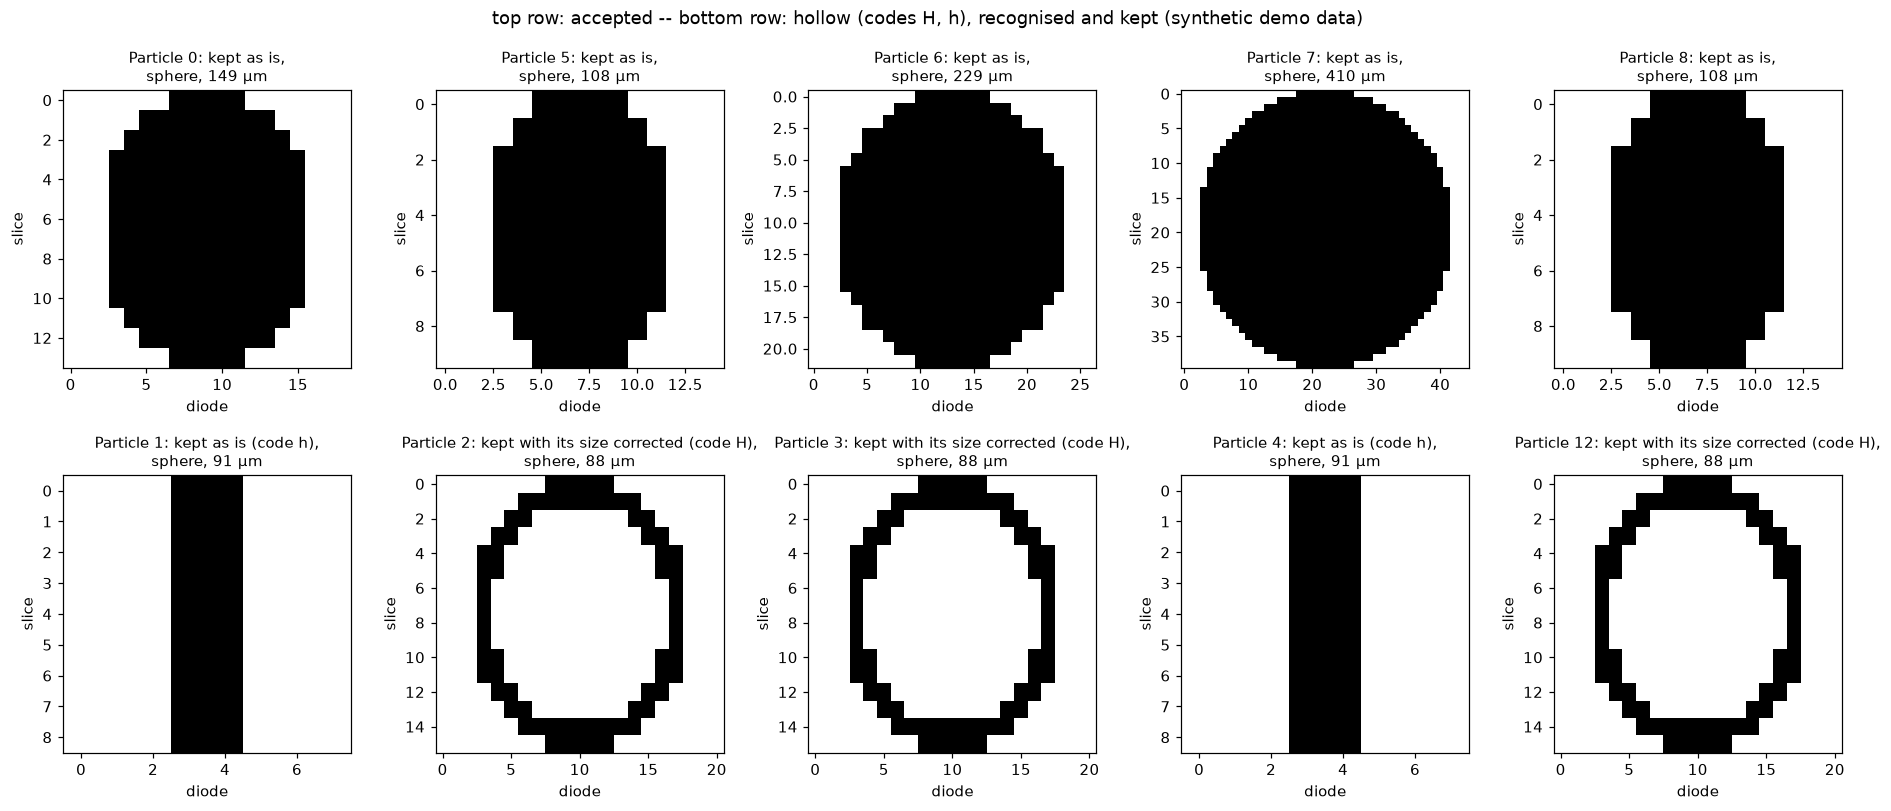

In [5]:
import matplotlib.pyplot as plt
import netCDF4   # the renderers take raw netCDF4 handles

from arrayprobe.render import render_contact_sheet
from arrayprobe_uiops.sizedist_core import GOOD_REJECT_CODES

kept = np.isin(reject, [ord(c) for c in GOOD_REJECT_CODES])  # v3.5 keeps 0, H, h, u, R
accepted = np.flatnonzero(reject == ord("0"))[:5]
rejected = np.flatnonzero(~kept)[:5]
second_row = "rejected"
if rejected.size == 0:  # stock v3.5 rejects none of the demo particles; use the hollow ones it recognises and keeps
    rejected = np.flatnonzero(kept & (reject != ord("0")))[:5]
    second_row = "hollow (codes H, h), recognised and kept"
with netCDF4.Dataset(image) as img_ds, netCDF4.Dataset(proc) as proc_ds:
    sheet = render_contact_sheet(img_ds, proc_ds, list(accepted) + list(rejected), ncols=5, crop=True)
sheet.set_size_inches(17, 7.5)
for ax, n in zip(sheet.axes, list(accepted) + list(rejected)):
    ax.set_title(plain_title(n, ax.get_title()), fontsize=10)
    ax.tick_params(labelsize=10)
    ax.xaxis.label.set_fontsize(10)
    ax.yaxis.label.set_fontsize(10)
sheet.suptitle(f"top row: accepted -- bottom row: {second_row} (synthetic demo data)", fontsize=12)
sheet.tight_layout()
plt.show()

*Figure 1. Ten particles from the synthetic demo flight, each cropped to its shadow. Top row: particles the reject stage accepted as they are. Bottom row: hollow particles, which v3.5 recognises and keeps. Each title gives the particle's index in the file, what the reject stage did, its habit and its size.*

## 4. The verdict store

The triage server writes every human (or bulk, or model) verdict to
`<decoded_dir>/triage_verdicts/<flight>.json`, next to the data and never inside it. Two
properties are enforced in code rather than promised:

- **every verdict names its source** (`human`, `bulk-cluster` or `model`), keyword-only with no
  default -- a label whose origin is unknown cannot be filtered out of a training set later;
- **an unreadable sidecar raises `VerdictStoreError`** instead of reading as "no labels", so a
  save can never overwrite labels it could not see.

The browser does this through the server; a script can do it through the same function, which
is what this cell does.

In [6]:
import json

from arrayprobe import triage_server

triage_server._save_verdict(decoded, FLIGHT, int(accepted[0]), "real", "looks like a drop",
                            source="human", reviewer="demo-reviewer")
triage_server._save_verdict(decoded, FLIGHT, int(rejected[0]), "unsure", "a bar, or an artefact?",
                            source="human", reviewer="demo-reviewer")
store = decoded / "triage_verdicts" / f"{FLIGHT}.json"
print(store.relative_to(decoded).as_posix())
for idx, rec in json.loads(store.read_text(encoding="utf-8")).items():
    print(f"  particle {idx}: {rec['verdict']:7s} source={rec['source']} reviewer={rec['reviewer']}"
          f" note={rec['note']!r}")

try:
    triage_server._save_verdict(decoded, FLIGHT, 0, "accept", source="guess")
except ValueError as exc:
    print("refused:", str(exc).split(";")[0])

# The proc file is untouched -- labels live beside it, not in it.
with xr.open_dataset(proc, mask_and_scale=False, decode_times=False) as ds:
    unchanged = np.array_equal(np.asarray(ds["image_auto_reject"][:]).astype(int), reject)
print("proc reject codes unchanged after labelling:", unchanged)

triage_verdicts/base160101000000.H.json
  particle 0: real    source=human reviewer=demo-reviewer note='looks like a drop'
  particle 1: unsure  source=human reviewer=demo-reviewer note='a bar, or an artefact?'
refused: verdict source 'guess' is not one of ['bulk-cluster', 'human', 'model']
proc reject codes unchanged after labelling: True


## 4b. Labelling features: comment, `mixed`, `--reviewer`, readable queue titles

The browser viewer adds a free-text comment box beside the four verdict buttons
(`artifact`/`real`/`mixed`/`unsure`), each bound to a key (`a`/`r`/`t`/`u`, `&larr;`/`p` and
`&rarr;`/`n` to move, `Esc` to leave the comment box so the keys work again) --
`docs/developer/LABELLING_PROTOCOL.md` §3. `mixed` ("two particles") exists because reviewers
were recording a real droplet beside an artifact as `unsure`, which poisons a bucket meant for
"could not tell".

Two more pieces of provenance travel with every label made from a running server, neither
posted by the page itself: `--reviewer`/`ARRAYPROBE_REVIEWER` names who is labelling, for the
whole session (server state, so no page can decide whose label this is); and a queue's own
sample-provenance name (`U-z__S-accepted`) is rendered in words by `describe_queue`, so a
reviewer never holds a reject-code table in their head while deciding.</cell>


In [7]:
from arrayprobe.triage_server import REVIEWER_ENV, VALID_VERDICTS, describe_queue

print("verdict vocabulary:", sorted(VALID_VERDICTS))

triage_server._save_verdict(decoded, FLIGHT, int(rejected[1]), "mixed",
                            source="human", reviewer="demo-reviewer",
                            comment="a real droplet beside a stuck diode -- both in one image")
after = json.loads(store.read_text(encoding="utf-8"))[str(int(rejected[1]))]
print(f"particle {int(rejected[1])}: verdict={after['verdict']!r} comment={after['comment']!r}")

print(f"\n{REVIEWER_ENV} sets --reviewer for a whole `arrayprobe triage` session; unset, the "
      "startup banner says so and labels record no reviewer at all.")

print("\nqueue title, raw name (what files and scores key on) vs. rendered (what a labeller reads):")
for name in ("U-z__S-accepted", "U-imgproc_i__S-interarrival"):
    print(f"  {name!r}\n    -> {describe_queue(name)!r}")

verdict vocabulary: ['artifact', 'mixed', 'real', 'unsure']
particle 2: verdict='mixed' comment='a real droplet beside a stuck diode -- both in one image'

ARRAYPROBE_REVIEWER sets --reviewer for a whole `arrayprobe triage` session; unset, the startup banner says so and labels record no reviewer at all.

queue title, raw name (what files and scores key on) vs. rendered (what a labeller reads):
  'U-z__S-accepted'
    -> "UIOPS rejects: area ratio below sizeDist's threshold (0.5 ORACLES fork, 0.2 stock) · SODA-2 accepts"
  'U-imgproc_i__S-interarrival'
    -> 'UIOPS rejects: side scans contradict the hollow verdict · SODA-2 rejects: inter-arrival time'


## 5. A review queue, and the server itself

A queue file is an ordered, named particle list for a curated pass -- `{"queue_name": [{"flight",
"particle_index", "note"}, ...]}`. The command a user runs is

```bash
arrayprobe triage --decoded-dir <decoded> --queue-file queue.json   # then open http://127.0.0.1:8765/
```

which blocks until Ctrl+C (`--port` changes the port; `--decoded-dir` is required on the CLI,
deliberately). Here the same handler is started on a free port in a background thread, asked
for two pages, and shut down, so the notebook can show it answering without blocking.

In [8]:
import threading
import urllib.request
from http.server import ThreadingHTTPServer

queue_file = Path(tmp.name) / "queue.json"
queue_file.write_text(json.dumps({"rejected_first": [
    {"flight": FLIGHT, "particle_index": int(i), "note": f"reject code {chr(reject[i])}"}
    for i in rejected]}, indent=1), encoding="utf-8")
queues = triage_server._load_queue_file(queue_file)
print("queue file parsed:", {name: len(items) for name, items in queues.items()})

# The handler is configured through class attributes (as `triage_server.run` does); save and
# restore them so this cell leaves the imported module as it found it.
Handler = triage_server.TriageServer
saved = {k: Handler.__dict__[k] for k in ("decoded_dir", "queues", "log_message") if k in Handler.__dict__}
triage_server.TriageServer.decoded_dir = decoded
triage_server.TriageServer.queues = queues
triage_server.TriageServer.log_message = lambda self, *a: None  # keep request logs out of the notebook
server = ThreadingHTTPServer(("127.0.0.1", 0), triage_server.TriageServer)
thread = threading.Thread(target=server.serve_forever, daemon=True)
thread.start()
try:
    base = f"http://127.0.0.1:{server.server_address[1]}"
    for path, expect in (("/", FLIGHT.removesuffix(".H")), ("/queue", "rejected_first")):
        with urllib.request.urlopen(base + path, timeout=30) as resp:
            body = resp.read().decode("utf-8", "replace")
        print(f"GET {path:7s} -> HTTP {resp.status}, {len(body):,} bytes, "
              f"page names {expect!r}: {expect in body}")
finally:
    server.shutdown()
    server.server_close()
    for k in ("decoded_dir", "queues", "log_message"):
        if k in saved:
            setattr(Handler, k, saved[k])
        elif k in Handler.__dict__:
            delattr(Handler, k)

queue file parsed: {'rejected_first': 5}
GET /       -> HTTP 200, 19,419 bytes, page names 'base160101000000': True
GET /queue  -> HTTP 200, 17,517 bytes, page names 'rejected_first': True


## 6. Figures for a reviewer

Three views a reviewer of a labelling pass usually asks for, built only from what this notebook
has already made: the labelled particles with their verdicts, the counts behind them, and what
the piece-gap setting does to a multi-piece image. All particles are synthetic. The first
cell again opens the files with `netCDF4`, because the renderer reads the raw on-disk variables.

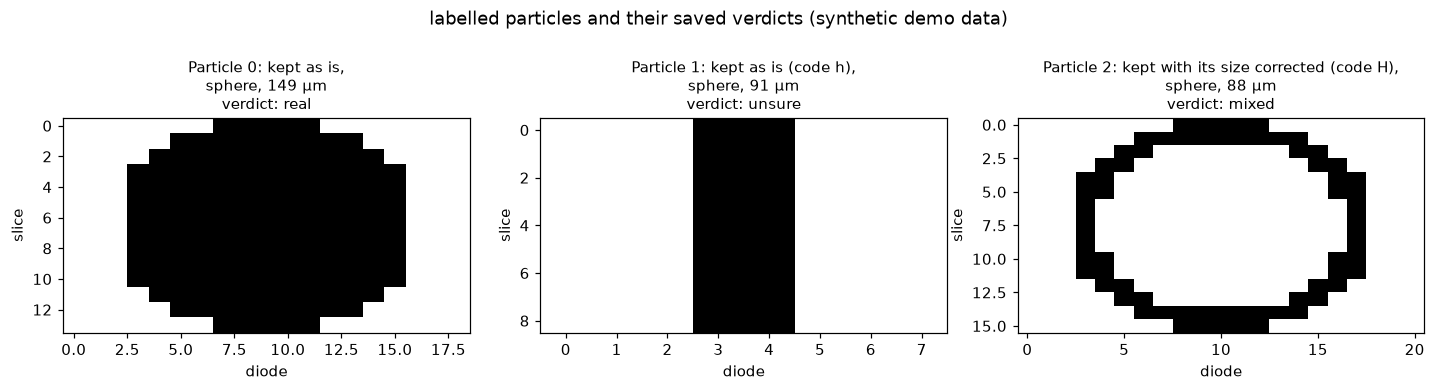

In [9]:
# 6a. The labelled particles, each titled with what the reject stage did, its habit, size and the verdict saved.
from arrayprobe.render import render_particle

labels = json.loads(store.read_text(encoding="utf-8"))
fig, axes = plt.subplots(1, len(labels), figsize=(4.4 * len(labels), 3.6))
with netCDF4.Dataset(image) as img_ds, netCDF4.Dataset(proc) as proc_ds:
    for ax, (idx, rec) in zip(np.atleast_1d(axes), sorted(labels.items(), key=lambda kv: int(kv[0]))):
        render_particle(img_ds, proc_ds, int(idx), ax=ax, crop=True)
        ax.set_title(f"{plain_title(idx, ax.get_title())}\nverdict: {rec['verdict']}", fontsize=10)
        ax.tick_params(labelsize=10)
        ax.xaxis.label.set_fontsize(10)
        ax.yaxis.label.set_fontsize(10)
fig.suptitle("labelled particles and their saved verdicts (synthetic demo data)", fontsize=12)
fig.tight_layout()
plt.show()

*Figure 2. The two particles this notebook labelled, from the synthetic demo flight, each titled with what the reject stage did, its habit, its size and the verdict saved in the verdict store. The verdict sits beside the computed values and changes none of them.*

reject codes: {'0': 160, 'H': 40, 'h': 40} | verdicts: {'real': 1, 'unsure': 1, 'mixed': 1}


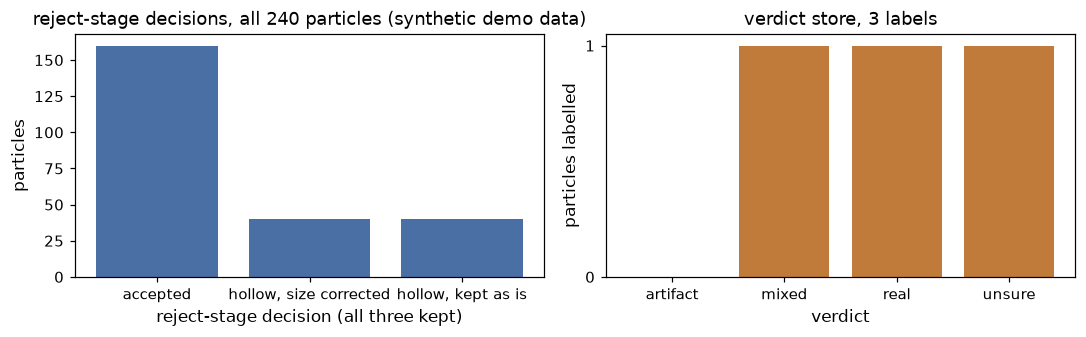

In [10]:
# 6b. Counts: what the reject stage decided for the whole flight, and what the reviewer said.
from collections import Counter

by_code = Counter(chr(c) for c in reject)
by_verdict = Counter(rec["verdict"] for rec in labels.values())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))
names = sorted(by_code, key=lambda k: (k != "0", k))
words = {"0": "accepted", "H": "hollow, size corrected", "h": "hollow, kept as is", "u": "hollow, small hole, kept", "R": "re-accepted"}
ax1.bar([words.get(k, f"rejected ({k})") for k in names], [by_code[k] for k in names], color="#4a6fa5")
ax1.set_xlabel("reject-stage decision (all three kept)")
ax1.set_ylabel("particles")
ax1.set_title(f"reject-stage decisions, all {reject.size} particles (synthetic demo data)")
verdicts = sorted(VALID_VERDICTS)
ax2.bar(verdicts, [by_verdict.get(v, 0) for v in verdicts], color="#c07a3a")
ax2.set_xlabel("verdict")
ax2.set_ylabel("particles labelled")
ax2.set_title(f"verdict store, {sum(by_verdict.values())} labels")
ax2.yaxis.get_major_locator().set_params(integer=True)
fig.tight_layout()
plt.show()
print("reject codes:", dict(sorted(by_code.items())), "| verdicts:", dict(by_verdict))

*Figure 3. Left: how many particles of the synthetic demo flight each reject-stage decision covers; every particle is kept. Right: how many labels of each verdict the store holds after this notebook's three saves.*

### 6c. The piece-gap setting

A "two particles" sub-label numbers the image's pieces, and what counts as one piece is set by
`arrayprobe.triage_context.piece_groups(mask, gap, scale)`. The default, `scale="constant"`,
joins two 8-connected components when the empty pixels between them number at most `gap`. The
opt-in `scale="larger"` joins them only when the gap is at most `min(gap, extent of the larger
component)`, so a fragment beside a large particle is absorbed while two specks the same
distance apart stay separate. The synthetic image below has a large body with a satellite six
pixels off it, and two 2-pixel specks five pixels apart. Under the opt-in rule the specks stay apart until the cap
is large enough for the body to reach them, at which point everything is one piece.

gap  0: constant -> 4 pieces, larger -> 4 pieces
gap  5: constant -> 3 pieces, larger -> 4 pieces
gap  6: constant -> 2 pieces, larger -> 3 pieces
gap 12: constant -> 1 pieces, larger -> 1 pieces


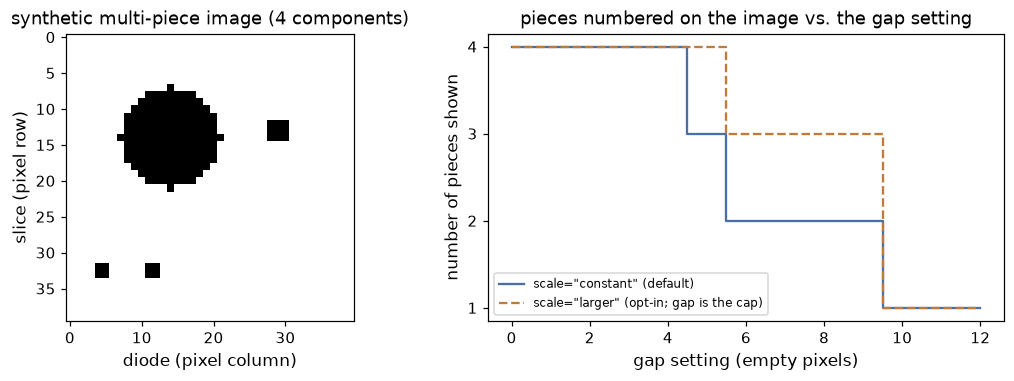

In [11]:
from arrayprobe.triage_context import piece_groups

mask = np.zeros((40, 40), dtype=bool)
yy, xx = np.mgrid[:40, :40]
mask |= (yy - 14) ** 2 + (xx - 14) ** 2 <= 49          # body, 15 pixels across
mask[12:15, 28:31] = True                               # satellite, 6 empty pixels right of the body
mask[32:34, 4:6] = True                                 # speck 1
mask[32:34, 11:13] = True                               # speck 2, 5 empty pixels from speck 1

gaps = list(range(0, 13))
n_const = [len(piece_groups(mask, g)) for g in gaps]
n_larger = [len(piece_groups(mask, g, scale="larger")) for g in gaps]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
ax1.imshow(mask, cmap="Greys", interpolation="nearest")
ax1.set_title("synthetic multi-piece image (4 components)")
ax1.set_xlabel("diode (pixel column)")
ax1.set_ylabel("slice (pixel row)")
ax2.step(gaps, n_const, where="mid", label='scale="constant" (default)', color="#4a6fa5")
ax2.step(gaps, n_larger, where="mid", label='scale="larger" (opt-in; gap is the cap)',
         color="#c07a3a", linestyle="--")
ax2.set_xlabel("gap setting (empty pixels)")
ax2.set_ylabel("number of pieces shown")
ax2.set_yticks(range(1, 5))
ax2.legend(fontsize=8)
ax2.set_title("pieces numbered on the image vs. the gap setting")
fig.tight_layout()
plt.show()
for g in (0, 5, 6, 12):
    print(f"gap {g:2d}: constant -> {len(piece_groups(mask, g))} pieces, "
          f"larger -> {len(piece_groups(mask, g, scale='larger'))} pieces")

*Figure 4. Left: a synthetic image of four pieces -- a large body, a satellite six empty pixels off it, and two specks five pixels apart. Right: how many pieces are numbered as the gap setting grows, under the default rule and the opt-in rule.*

## Where to go next

- `docs/developer/LABELLING_PROTOCOL.md` -- the labelling protocol in full.
- [`05_triage_and_gallery.ipynb`](../1_getting_started/05_triage_and_gallery.ipynb) -- look at particles as a contact sheet and a gallery, and start the triage page to label them.
- `docs/03-visualisation.md` -- the gallery and triage server, including the `/clusters` bulk-labelling route.
